In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error, r2_score

In [2]:
data = fetch_california_housing(as_frame=True)
df = pd.concat([data.data, data.target.rename("HousePrice")], axis=1)
X = df.drop("HousePrice", axis=1)
y = df["HousePrice"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [3]:
tree = DecisionTreeRegressor(random_state=42)
tree.fit(X_train_s, y_train)
train_rmse = root_mean_squared_error(y_train, tree.predict(X_train_s))
test_rmse = root_mean_squared_error(y_test, tree.predict(X_test_s))
print(f"Train RMSE: {train_rmse:.4f} | Test RMSE: {test_rmse:.4f} | Gap: {test_rmse - train_rmse:.4f}")

def cv_rmse(model):
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    return -cross_val_score(pipe, X_train, y_train, scoring="neg_root_mean_squared_error", cv=5)

cv_results = {}
for name, m in {"Linear Regression": LinearRegression(),
                "Ridge Regression": Ridge(alpha=1.0),
                "Decision Tree (untuned)": DecisionTreeRegressor(random_state=42)}.items():
    s = cv_rmse(m)
    cv_results[name] = s
    print(f"{name:25s} CV RMSE = {s.mean():.4f} (+/- {s.std():.4f})")

Train RMSE: 0.0000 | Test RMSE: 0.7021 | Gap: 0.7021
Linear Regression         CV RMSE = 0.7205 (+/- 0.0103)
Ridge Regression          CV RMSE = 0.7205 (+/- 0.0103)
Decision Tree (untuned)   CV RMSE = 0.7253 (+/- 0.0206)


In [4]:
tree_pipe = Pipeline([("scaler", StandardScaler()), ("model", DecisionTreeRegressor(random_state=42))])
tree_grid = {"model__max_depth": [3, 5, 7, 10], "model__min_samples_split": [2, 5, 10]}
grid_tree = GridSearchCV(tree_pipe, tree_grid, scoring="neg_root_mean_squared_error", cv=5)
grid_tree.fit(X_train, y_train)
print("Best Tree params:", grid_tree.best_params_, "| CV RMSE:", -grid_tree.best_score_)

ridge_pipe = Pipeline([("scaler", StandardScaler()), ("model", Ridge())])
ridge_grid = {"model__alpha": [0.01, 0.1, 1, 10, 100]}
grid_ridge = GridSearchCV(ridge_pipe, ridge_grid, scoring="neg_root_mean_squared_error", cv=5)
grid_ridge.fit(X_train, y_train)
print("Best Ridge params:", grid_ridge.best_params_, "| CV RMSE:", -grid_ridge.best_score_)

Best Tree params: {'model__max_depth': 10, 'model__min_samples_split': 10} | CV RMSE: 0.6374956796940052
Best Ridge params: {'model__alpha': 0.01} | CV RMSE: 0.7205271904045847


In [5]:
lr = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]).fit(X_train, y_train)
best_ridge = grid_ridge.best_estimator_
best_tree = grid_tree.best_estimator_

def evaluate(model):
    p = model.predict(X_test)
    return root_mean_squared_error(y_test, p), r2_score(y_test, p)

lr_rmse, lr_r2 = evaluate(lr)
ridge_rmse, ridge_r2 = evaluate(best_ridge)
rmse, r2 = evaluate(best_tree)

tuned_train_rmse = root_mean_squared_error(y_train, best_tree.predict(X_train))
print(f"Untuned gap: {test_rmse - train_rmse:.4f} -> Tuned gap: {rmse - tuned_train_rmse:.4f}")

results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression (tuned)", "Decision Tree (tuned)"],
    "CV RMSE": [cv_results["Linear Regression"].mean(), -grid_ridge.best_score_, -grid_tree.best_score_],
    "Test RMSE": [lr_rmse, ridge_rmse, rmse],
    "Test R2": [lr_r2, ridge_r2, r2],
})
results.round(4)

Untuned gap: 0.7021 -> Tuned gap: 0.1650


,Model,CV RMSE,Test RMSE,Test R2
0,Linear Regression,0.7205,0.7456,0.5758
1,Ridge Regression (tuned),0.7205,0.7456,0.5758
2,Decision Tree (tuned),0.6375,0.6454,0.6822


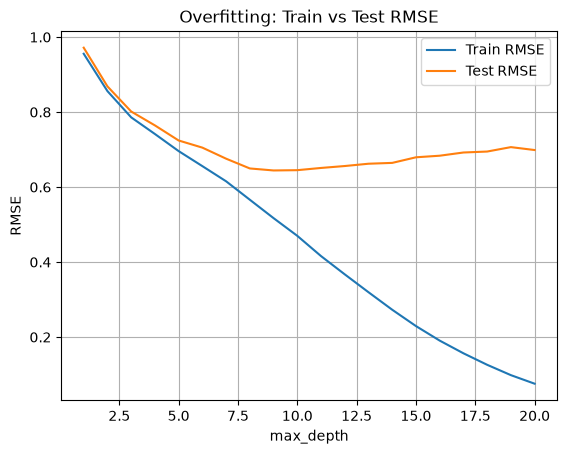

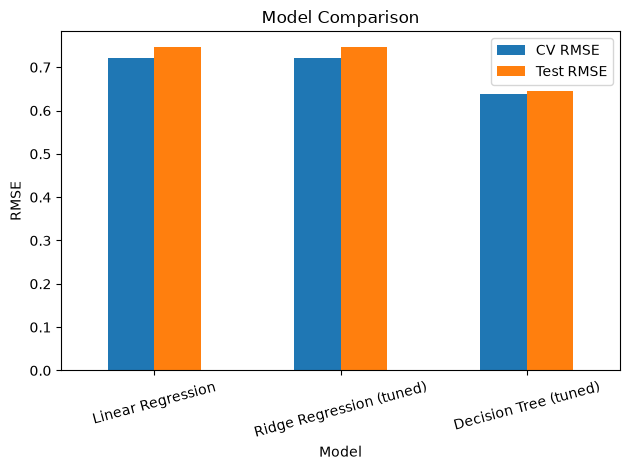

Saved: Decision Tree (tuned)


In [6]:
depths = range(1, 21)
tr, te = [], []
for d in depths:
    t = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_train_s, y_train)
    tr.append(root_mean_squared_error(y_train, t.predict(X_train_s)))
    te.append(root_mean_squared_error(y_test, t.predict(X_test_s)))
plt.plot(depths, tr, label="Train RMSE")
plt.plot(depths, te, label="Test RMSE")
plt.xlabel("max_depth"); plt.ylabel("RMSE"); plt.title("Overfitting: Train vs Test RMSE")
plt.legend(); plt.grid(True); plt.savefig("overfitting_curve.png", dpi=150); plt.show()

results.set_index("Model")[["CV RMSE", "Test RMSE"]].plot(kind="bar")
plt.ylabel("RMSE"); plt.title("Model Comparison"); plt.xticks(rotation=15)
plt.tight_layout(); plt.savefig("model_comparison.png", dpi=150); plt.show()

best_name = results.sort_values("CV RMSE").iloc[0]["Model"]
final_model = {"Linear Regression": lr, "Ridge Regression (tuned)": best_ridge, "Decision Tree (tuned)": best_tree}[best_name]
joblib.dump(final_model, "best_house_price_model.joblib")
print("Saved:", best_name)